**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



**Set global variable**

In [2]:
## init: region folder
vec = c("fcc_astarr_macs_input_overlap", "fcc_astarr_macs_input_union")
names(vec) = vec

VEC_TXT_FOLDER = vec
for (txt in vec) {cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


**Check input files**

In [3]:
txt_folder = "fcc_astarr_macs_input_union"
txt_fdiry  = file.path(FD_RES, "analysis_fcc_correlation", txt_folder)
txt_fname  = "*distance_correlation*"
txt_fglob  = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for (txt in vec) {cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_correlation/fcc_astarr_macs_input_union/result.cripsr_vs_starrmpra.distance_correlation.tsv 


## Import data

In [4]:
### set file directory
txt_foldr = "fcc_astarr_macs_input_union"
txt_fdiry = file.path(FD_RES, "analysis_fcc_correlation", txt_foldr)
txt_fname = "result.cripsr_vs_starrmpra.spearman_correlation.tsv"
txt_fpath = file.path(txt_fdiry, txt_fname)

### read table
dat = read_tsv(txt_fpath, show_col_types = FALSE)

### assign and show
dat_assay_scor = dat
print(dim(dat))
fun_display_table(head(dat))

[1] 210   5


CutOff_CRISPR,Assay_CRISPR,Assay_STARRMPRA,size,scor
0.01,CRISPRi-HCRFF,ASTARR,14,0.2263736
0.01,CRISPRi-HCRFF,WSTARR,14,0.2703297
0.01,CRISPRi-HCRFF,LMPRA,12,0.2276711
0.01,CRISPRi-HCRFF,TMPRA,7,0.1785714
0.01,CRISPRi-HCRFF,ATAC,14,0.5736264
0.01,CRISPRi-Growth,ASTARR,803,0.2691445


## Explore: Spearman correlation

`geom_smooth()` using formula = 'y ~ x'


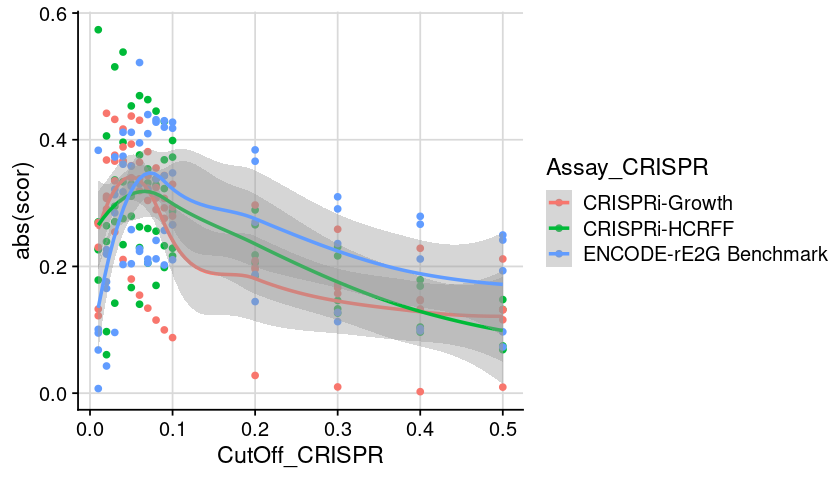

In [5]:
dat = dat_assay_scor
gpt = ggplot(dat, aes(x=CutOff_CRISPR, y = abs(scor), group = Assay_CRISPR, color = Assay_CRISPR)) +
    geom_point() +
    geom_smooth(method = "loess") +
    theme_cowplot() +
    background_grid()

options(repr.plot.height=4, repr.plot.width=7)
print(gpt)

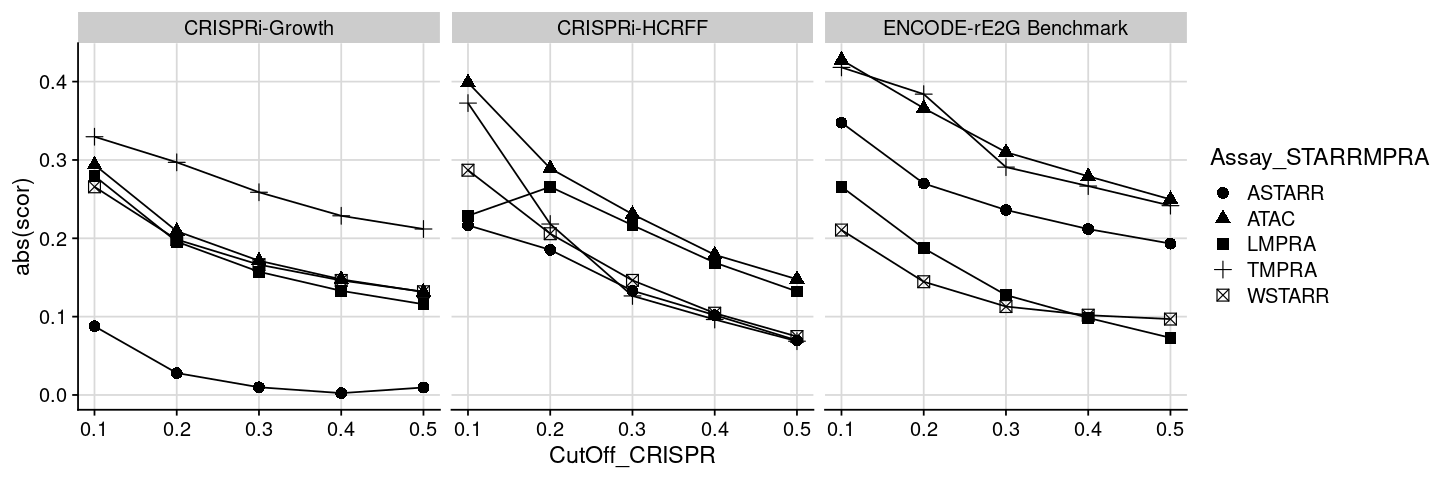

In [6]:
dat = dat_assay_scor
dat = dat %>% dplyr::filter(CutOff_CRISPR >= 0.1)
gpt = ggplot(dat, aes(x=CutOff_CRISPR, y = abs(scor), group = Assay_STARRMPRA, shape = Assay_STARRMPRA)) +
    geom_line() +
    geom_point(size = 3) +
    theme_cowplot() +
    background_grid() +
    facet_wrap(~Assay_CRISPR)

options(repr.plot.height=4, repr.plot.width=12)
print(gpt)

## Export figure

**Set text style**

In [7]:
THEME_TEXT = theme(
    title        = element_text(size = 16),
    axis.text.x  = element_text(size = 16),
    axis.text.y  = element_text(size = 16),
    axis.title.x = element_text(size = 16),
    axis.title.y = element_text(size = 16),
    legend.text  = element_text(size = 14),
    legend.title = element_text(size = 14),
    strip.text   = element_text(size = 16, face = "bold", hjust = 0),
    strip.background = element_rect(fill = "white")
)

**Generate plots**

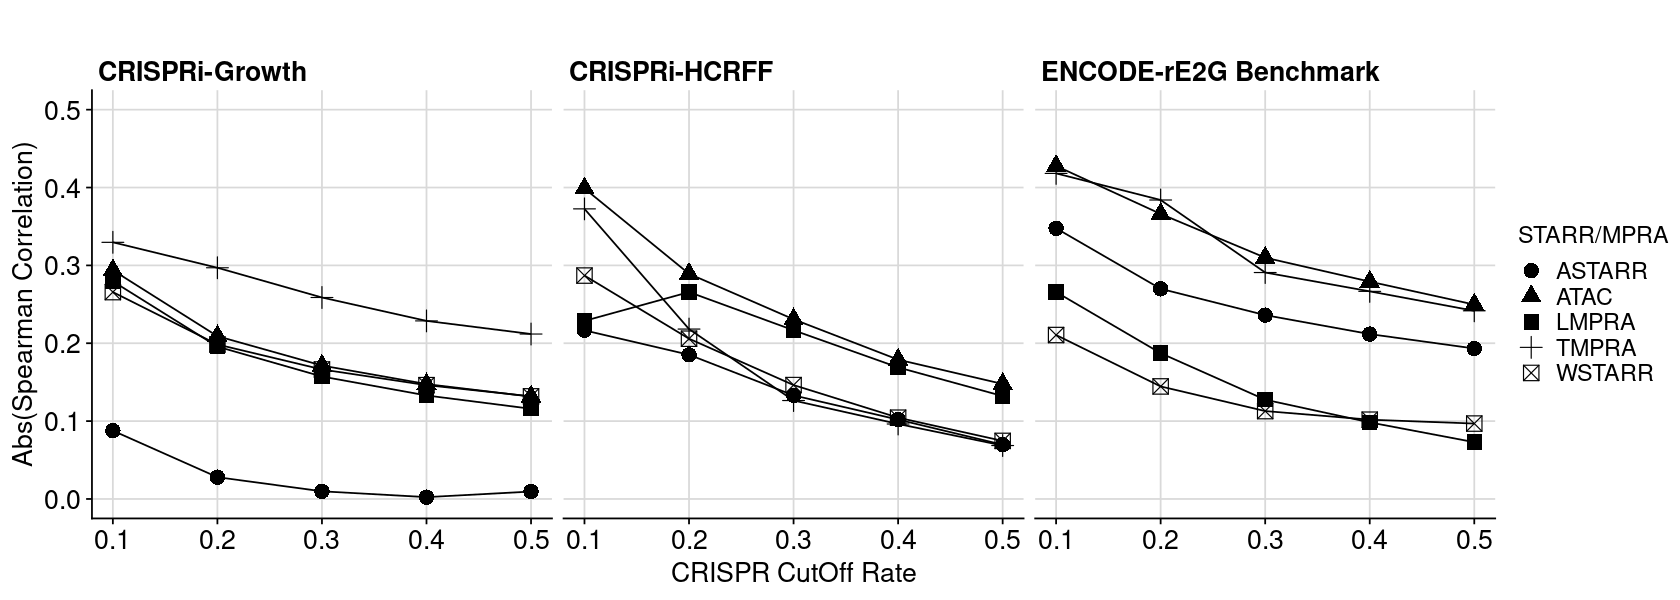

In [8]:
dat = dat_assay_scor
dat = dat %>% dplyr::filter(CutOff_CRISPR >= 0.1)
gpt = ggplot(dat, aes(x=CutOff_CRISPR, y = abs(scor), group = Assay_STARRMPRA, shape = Assay_STARRMPRA)) +
    geom_line() +
    geom_point(size = 4) +
    #geom_smooth(method = "loess") +
    theme_cowplot() +
    background_grid() +
    labs(
        x="CRISPR CutOff Rate", 
        y = "Abs(Spearman Correlation)", 
        title = "",
        shape = "STARR/MPRA"
    ) +
    facet_wrap(~Assay_CRISPR) +
    ylim(0.0, 0.5) +
    THEME_TEXT

### assign and show
gpt_export_scor = gpt
options(repr.plot.height=5, repr.plot.width=14)
print(gpt)

**Export plots**

In [9]:
plt_export = gpt_export_scor
txt_export = "fig.region_coverage_fcc.corr.spearman.crispr_vs_starrmpra"
num_height = 5
num_width  = 14

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")